<a href="https://colab.research.google.com/github/ONESFA/PINNs-and-FDM-FEM/blob/main/notebooks/PINNS_v5_pulse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINN v5: 좁은 초기 펄스에서 중요도 기반 샘플링 비교

v4 에서는 초기조건 $u_0=\sin\pi x\,\sin\pi y$ 처럼 매끄러운 문제에서 중요도 기반 샘플링(건너뛰기 + 잔차 기반)의 이득이 거의 없었습니다. 해가 고유모드 하나라 잔차가 영역 전체에 고르게 퍼져 있어, 점을 "몰아줄 곳"이 따로 없기 때문입니다.

이 노트북은 **폭이 좁은 돌 충격(가우시안 펄스) 3개**를 초기조건으로 씁니다. 해의 대부분은 평평하고, 파면만 좁은 고리 모양으로 퍼져 나갑니다. 잔차도 파면에 몰리므로, 점을 파면에 모으는 샘플링이 효과를 낼 수 있는 문제입니다.

$$u_{tt}=c^2(u_{xx}+u_{yy}),\quad (x,y)\in[0,1]^2,\qquad u|_{\partial\Omega}=0,\qquad u(x,y,0)=\sum_{s=1}^{3}a_s\,e^{-\frac{(x-x_s)^2+(y-y_s)^2}{2\sigma^2}},\qquad u_t(x,y,0)=0$$

| 번호 | 내용 |
|---|---|
| 0 | 설정 (모든 하이퍼파라미터) |
| 1 | 초기조건, **고해상도 FDM 기준해** (정확해가 없으므로), 테스트 점 |
| 2 | 신경망 (v3 의 PINN + Fourier feature 입력) |
| 3 | 손실 (인과성 가중치 포함) |
| 4 | PDE 점 샘플링: `uniform` / `rad` / `skip+rad` |
| 5 | 학습 함수 `run(mode, N_f, seed)` |
| 6 | 한 번 실행하고 결과 보기 (`MODE`, `N_f`) |
| 7 | **비교 실험**: 세 방식 × 여러 $N_f$ 를 차례로 실행하고 "오차 vs 점 수" 를 그림 |

세 방식 모두 같은 신경망, 같은 손실, 같은 인과성 가중치, 같은 학습 횟수를 씁니다. **PDE 내부 점을 뽑는 방법만** 다릅니다.

# **0번 설정**

In [ ]:
import time
import math
import copy
import json
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ============================================
# 0. 실험 설정 — 하이퍼파라미터는 전부 이 셀에서만 바꾼다
# ============================================
SEED = 0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("[경고] GPU 가 꺼져 있습니다. Colab: 런타임 -> 런타임 유형 변경 -> T4 GPU 후 처음부터 다시 실행.\n"
          "       TPU 런타임도 이 코드(PyTorch CUDA)에서는 CPU 로 돌아갑니다. 반드시 GPU 를 고르세요.")

# --- 문제: 좁은 초기 펄스 (돌 3개) ---
T = 0.6                      # 시간 영역 [0, T]
C = 1.0                      # 파동 속도
STONES = [(0.30, 0.35, 1.00),        # (x, y, 진폭) — 연못 역문제 노트북과 같은 배치
          (0.68, 0.30, 0.70),
          (0.55, 0.72, 0.85)]
SIGMA = 0.05                 # 펄스 폭 (가우시안 표준편차). 작을수록 파면이 좁고 어려워진다

# --- 기준해: 고해상도 FDM ---
REF_NX = 401                 # 기준해 격자 한 변의 점 수 (h = 1/400)
REF_NT = 61                  # 기준해를 저장하는 시각 수 (0 ~ T 등간격)
FDM_CFL = 0.5                # c*dt/h  (2차원 안정 조건 c*dt/h <= 1/sqrt(2))
FDM_CMP_NX = 101             # 비교용 일반 해상도 FDM
N_TEST = 20000               # 오차 평가용 고정 테스트 점 (기준해 격자점 x 저장 시각에서 뽑음)

# --- 신경망 ---
WIDTH, DEPTH = 64, 4         # 은닉층 폭, 은닉층 수
FOURIER_SIGMA = 2.0          # > 0 이면 random Fourier feature 입력 (좁은 펄스 표현에 필요, 0 = 끔)
N_FOURIER = 64
N_IC = 2000                  # 초기조건 점 (매 epoch 새로 뽑음)
W_IC_GRAD = 1.0              # 초기 변위 기울기 손실의 가중치 (v3 와 같은 항, 0 = 끔)
W_PDE = 100                  # PDE 손실 가중치 (잔차는 이미 sigma^2 로 크기를 맞춤)

# --- PDE 점 샘플링 (6번 한 번 실행에 쓰는 값) ---
MODE = "uniform"             # "uniform" (균등) | "rad" (잔차 기반) | "skip+rad" (건너뛰기 + 잔차 기반)
N_f = 4000                   # PDE 내부 점 개수.  처음에는 uniform + 넉넉한 점으로 이 문제가 학습되는지 확인 (6번)
AS_EVERY = 100               # 후보 점의 잔차를 다시 계산하는 주기 (epoch)
AS_POOL_FACTOR = 10          # 후보 점 개수 = AS_POOL_FACTOR * N_f
AS_K = 1.0                   # 중요도 지수 k: 클수록 잔차가 큰 곳에 더 몰린다
AS_C = 1.0                   # 중요도 바닥값 c: 클수록 균등에 가깝다 (c > 0 이면 어느 곳도 확률 0 이 아님)
AS_SKIP_TOL = 1e-3           # skip: 인과성 가중치가 이보다 작은 시간 bin 에는 점을 뽑지 않는다
LBFGS_ADAPTIVE = True        # L-BFGS 의 고정 점도 같은 방식으로 뽑는다 (False 면 v4 처럼 항상 균등)

# --- 인과성 가중치 (세 방식 모두 사용) ---
TM_CAUSAL_N_CHUNKS = 32
TM_CAUSAL_EPS_LIST = [10.0, 100.0, 1000.0]
TM_CAUSAL_DELTA = 0.99       # min_i w_i > delta 이면 다음 eps 로

# --- 최적화 ---
EPOCHS_ADAM = 20000
LR_START, LR_END = 1e-3, 1e-5
USE_LBFGS = False
LBFGS_CHUNKS = 20
LBFGS_ITERS_PER_CHUNK = 50
EVAL_EVERY = 100             # 상대 L2 오차 계산 주기 (epoch)
PRINT_EVERY = 1000           # 로그 간격 (epoch)

# --- 7번 비교 실험 ---
RUN_SWEEP = True            # 6번에서 학습이 되는 것을 확인한 뒤 True 로 바꿔 다시 실행 (T4 에서 수십 분)
SWEEP_MODES = ["uniform", "rad", "skip+rad"]
SWEEP_NF = [1000, 4000]
SWEEP_SEEDS = [0]
QUICK = False                # True: 빠른 확인용 (Adam 2000, L-BFGS 4 chunk, N_f 2개)

if QUICK:
    EPOCHS_ADAM, LBFGS_CHUNKS, SWEEP_NF = 2000, 4, [500, 2000]
    print(f"QUICK 설정: EPOCHS_ADAM={EPOCHS_ADAM}, LBFGS_CHUNKS={LBFGS_CHUNKS}, SWEEP_NF={SWEEP_NF}")


def sync():
    """GPU 연산은 비동기이므로 시간 측정 직전에 동기화한다."""
    if device.type == "cuda":
        torch.cuda.synchronize()


def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)


set_seed(SEED)

device: cuda


# **1번 초기조건과 기준해**

정확해가 없으므로 **고해상도 FDM**(격자 $401\times401$, 중앙차분 leapfrog)으로 기준해를 만듭니다. 격자를 절반($201\times201$)으로 줄인 FDM 과의 차이를 출력해 기준해가 충분히 정확한지 확인합니다.
PINN 의 상대 $L_2$ 오차는 기준해 격자점과 저장 시각에서 고정으로 뽑은 테스트 점 `N_TEST` 개로 계산합니다.

기준해 FDM: nx=401, nt=480, c dt/h=0.500, 0.8s
기준해 점검: nx=201 과 nx=401 의 상대 차이 2.84e-03  (2차 정확도라 nx=401 의 오차는 대략 이것의 1/3 이하)
FDM nx=101: 기준해 대비 상대 L2 오차 1.42e-02, 계산 0.011s


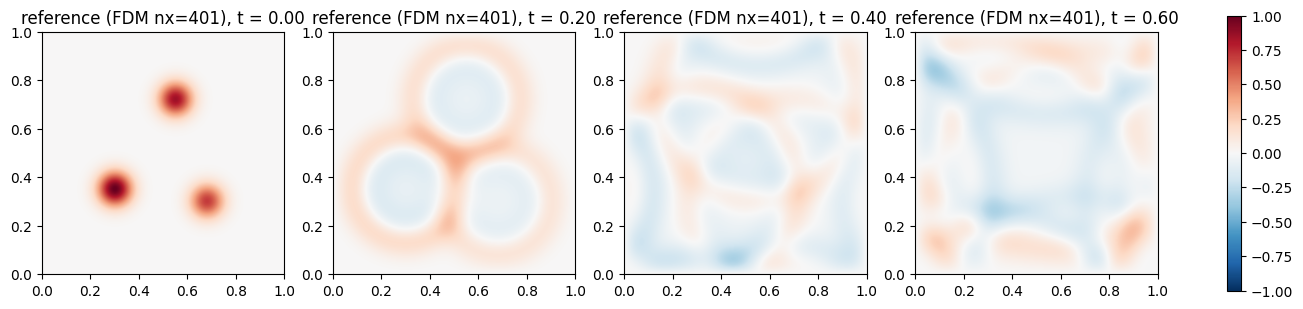

In [ ]:
# ============================================
# 1. 초기조건, FDM, 기준해, 테스트 점
# ============================================
def u0_stones(x, y):
    """초기 수면: 가우시안 펄스의 합. numpy 배열 / torch 텐서 모두 가능."""
    lib = torch if torch.is_tensor(x) else np
    u = 0.0 * x
    for xs, ys, a in STONES:
        u = u + a * lib.exp(-((x - xs) ** 2 + (y - ys) ** 2) / (2 * SIGMA ** 2))
    return u


def u0_grad(x, y):
    """초기 변위의 기울기 (u0_x, u0_y) — 초기 기울기 손실에 사용."""
    gx, gy = 0.0 * x, 0.0 * y
    for xs, ys, a in STONES:
        g = a * torch.exp(-((x - xs) ** 2 + (y - ys) ** 2) / (2 * SIGMA ** 2))
        gx = gx - g * (x - xs) / SIGMA ** 2
        gy = gy - g * (y - ys) / SIGMA ** 2
    return gx, gy


def fdm_wave_general(u0_fn, nx, T_end, c, cfl=FDM_CFL, n_save=REF_NT):
    """단위 정사각형, u = 0 경계, u(.,0) = u0_fn(X, Y), u_t(.,0) = 0. 명시적 중앙차분(leapfrog).
    0 ~ T_end 를 n_save 개 시각으로 나눈 시각마다 전체 격자를 저장. 반환: xs, ts, U[n_save, nx, nx], info"""
    h = 1.0 / (nx - 1)
    m = n_save - 1
    nt = math.ceil(T_end / (cfl * h / c))
    nt = m * math.ceil(nt / m)                    # 저장 시각이 정확히 시간 격자 위에 오도록
    dt = T_end / nt
    lam2 = (c * dt / h) ** 2
    assert 2 * lam2 <= 1.0 + 1e-12, f"CFL 위반: c dt / h = {math.sqrt(lam2):.3f}"
    every = nt // m

    xs = np.linspace(0.0, 1.0, nx)
    X, Y = np.meshgrid(xs, xs, indexing="xy")      # U[k, iy, ix]

    def lap(u):
        return u[2:, 1:-1] + u[:-2, 1:-1] + u[1:-1, 2:] + u[1:-1, :-2] - 4.0 * u[1:-1, 1:-1]

    t0 = time.time()
    U = np.zeros((n_save, nx, nx))
    u_prev = u0_fn(X, Y)
    u_prev[0, :] = u_prev[-1, :] = u_prev[:, 0] = u_prev[:, -1] = 0.0
    u_curr = np.zeros_like(u_prev)
    u_curr[1:-1, 1:-1] = u_prev[1:-1, 1:-1] + 0.5 * lam2 * lap(u_prev)   # u_t(.,0) = 0 인 2차 정확도 첫 단계
    U[0] = u_prev
    if every == 1:
        U[1] = u_curr
    u_next = np.zeros_like(u_prev)
    for n in range(1, nt):
        u_next[1:-1, 1:-1] = 2.0 * u_curr[1:-1, 1:-1] - u_prev[1:-1, 1:-1] + lam2 * lap(u_curr)
        u_prev, u_curr, u_next = u_curr, u_next, u_prev
        if (n + 1) % every == 0:
            U[(n + 1) // every] = u_curr
    info = dict(nx=nx, nt=nt, dt=dt, cfl=math.sqrt(lam2), time=time.time() - t0)
    return xs, np.linspace(0.0, T_end, n_save), U, info


# --- 기준해 ---
xs_ref, ts_ref, U_ref, info_ref = fdm_wave_general(u0_stones, REF_NX, T, C)
print(f"기준해 FDM: nx={info_ref['nx']}, nt={info_ref['nt']}, c dt/h={info_ref['cfl']:.3f}, {info_ref['time']:.1f}s")

# 기준해가 충분히 정확한가: 격자를 절반으로 줄인 FDM 과 비교 (공통 격자점)
_, _, U_half, _ = fdm_wave_general(u0_stones, (REF_NX + 1) // 2, T, C)
ref_check = np.linalg.norm(U_half - U_ref[:, ::2, ::2]) / np.linalg.norm(U_ref[:, ::2, ::2])
print(f"기준해 점검: nx={(REF_NX + 1) // 2} 과 nx={REF_NX} 의 상대 차이 {ref_check:.2e}  "
      f"(2차 정확도라 nx={REF_NX} 의 오차는 대략 이것의 1/3 이하)")
del U_half

# 비교용 일반 해상도 FDM (nx = FDM_CMP_NX) 의 오차
xs_cmp, _, U_cmp, info_cmp = fdm_wave_general(u0_stones, FDM_CMP_NX, T, C)
step = (REF_NX - 1) // (FDM_CMP_NX - 1)
fdm_cmp_err = np.linalg.norm(U_cmp - U_ref[:, ::step, ::step]) / np.linalg.norm(U_ref[:, ::step, ::step])
print(f"FDM nx={FDM_CMP_NX}: 기준해 대비 상대 L2 오차 {fdm_cmp_err:.2e}, 계산 {info_cmp['time']:.3f}s")

# --- 고정 테스트 점 (학습 난수와 분리) ---
rng = np.random.default_rng(1234)
k_t = rng.integers(0, REF_NT, N_TEST)
iy_t = rng.integers(1, REF_NX - 1, N_TEST)
ix_t = rng.integers(1, REF_NX - 1, N_TEST)
to_t = lambda a: torch.tensor(np.asarray(a, dtype=np.float32).reshape(-1, 1), device=device)
x_test, y_test, t_test = to_t(xs_ref[ix_t]), to_t(xs_ref[iy_t]), to_t(ts_ref[k_t])
u_test = to_t(U_ref[k_t, iy_t, ix_t])


def rel_l2(model):
    with torch.no_grad():
        return (torch.linalg.norm(model(x_test, y_test, t_test) - u_test) / torch.linalg.norm(u_test)).item()


# --- 기준해 그림 ---
show_k = [0, REF_NT // 3, 2 * REF_NT // 3, REF_NT - 1]
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
vmax = np.abs(U_ref).max()
for a, k in zip(ax, show_k):
    im = a.imshow(U_ref[k], origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    a.set_title(f"reference (FDM nx={REF_NX}), t = {ts_ref[k]:.2f}")
fig.colorbar(im, ax=ax, shrink=0.85)
plt.show()

# **2번 신경망**

v3 의 `PINN`(입력 정규화, hard BC $u=16x(1-x)y(1-y)N$)에 **random Fourier feature 입력**을 더했습니다. tanh MLP 는 좁은 펄스 같은 고주파 성분을 잘 배우지 못하기 때문입니다(spectral bias). 연못 역문제 노트북과 같은 구조입니다.

In [ ]:
class PINN(nn.Module):

    def __init__(self, width=WIDTH, depth=DEPTH, fourier_sigma=FOURIER_SIGMA, n_fourier=N_FOURIER):
        super().__init__()
        if fourier_sigma > 0:      # random Fourier feature: [sin(pi z B), cos(pi z B)]
            self.register_buffer("B", torch.randn(3, n_fourier) * fourier_sigma)
            n_in = 2 * n_fourier
        else:
            self.B = None
            n_in = 3
        layers = [nn.Linear(n_in, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.Tanh()]
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x, y, t):
        z = torch.cat([2 * x - 1, 2 * y - 1, 2 * t / T - 1], dim=1)    # [0,1]^2 x [0,T] -> [-1,1]^3
        if self.B is not None:
            z = math.pi * z @ self.B
            z = torch.cat([torch.sin(z), torch.cos(z)], dim=1)
        return 16.0 * x * (1 - x) * y * (1 - y) * self.net(z)        # hard BC: 경계에서 u = 0

# **3번 손실**

$$\mathcal L=\underbrace{\frac1{N_t}\sum_{i=1}^{N_t}w_i\,\mathrm{mean}_{t\in\text{bin }i}\big(\sigma^2 r\big)^2}_{\text{PDE (인과성 가중)}}+\mathrm{mean}\big(u_\theta(\cdot,0)-u_0\big)^2+\mathrm{mean}\big(\sigma\,u_{\theta,t}(\cdot,0)\big)^2+w_{g}\,\mathrm{mean}\big|\sigma(\nabla u_\theta(\cdot,0)-\nabla u_0)\big|^2$$

- 잔차 $r=u_{tt}-c^2\Delta u$ 는 펄스 폭 때문에 $u$ 의 $1/\sigma^2$ 배 크기라 $\sigma^2$ 를 곱해 초기조건 항과 크기를 맞춥니다. 1계 미분 항(초기 속도, 초기 기울기)에는 $\sigma$ 를 곱합니다.
- 인과성 가중치 $w_i=\exp(-\varepsilon\sum_{j<i}L_j)$ 는 v2~v4 와 같습니다. 세 샘플링 방식 모두 이 가중치를 씁니다.
- 잔차 기반 샘플링을 쓰면 bin 평균 손실이 실제보다 크게 나오므로, **가중치를 계산할 때만** 추출 밀도 $g$ 로 보정한 평균 $\sum(r^2/g)/\sum(1/g)$ 를 씁니다(v4 와 같음). 점을 뽑지 않은 bin 은 마지막으로 계산했던 손실 값을 씁니다.

In [ ]:
# ============================================
# PDE 잔차:  u_tt - c^2 (u_xx + u_yy)   (v3 와 같은 함수)
# ============================================
def pde_residual(model, x, y, t, c=C):
    x = x.clone().detach().requires_grad_(True)
    y = y.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)
    u = model(x, y, t)
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_y = torch.autograd.grad(u, y, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]
    u_tt = torch.autograd.grad(u_t, t, grad_outputs=torch.ones_like(u_t), create_graph=True)[0]
    return u_tt - c ** 2 * (u_xx + u_yy)


def causal_pde_loss(st, model, x, y, t, w_fixed=None):
    """시간 bin 별 PDE 손실을 인과성 가중치로 가중 평균. st 는 한 번의 학습 상태(5번 run 이 만든다)."""
    r2 = W_PDE * (SIGMA ** 2 * pde_residual(model, x, y, t)).pow(2).flatten()   # 크기 정규화한 잔차의 제곱
    Nt = TM_CAUSAL_N_CHUNKS
    idx = torch.clamp((t.detach().flatten() / T * Nt).long(), 0, Nt - 1)
    zero = torch.zeros(Nt, device=r2.device, dtype=r2.dtype)
    n_bin = torch.bincount(idx, minlength=Nt)
    L_t = zero.index_add(0, idx, r2) / n_bin.clamp_min(1).to(r2.dtype)    # (N_t,) bin 별 평균 (손실에 사용)

    # 가중치 계산용 bin 손실 L_w (손실 자체는 바꾸지 않는다)
    L_w = L_t.detach()
    q = st["q"]
    if q is not None and q.shape[0] == r2.shape[0]:      # 잔차 기반 추출의 편향 보정
        L_w = zero.index_add(0, idx, r2.detach() / q) / zero.index_add(0, idx, 1.0 / q).clamp_min(1e-30)
    if st["skip"] and w_fixed is None:                   # 점을 뽑지 않은 bin: 마지막으로 계산했던 값
        if st["L_last"] is not None:
            L_w = torch.where(n_bin > 0, L_w, st["L_last"])
        st["L_last"] = L_w

    if w_fixed is None:
        eps = TM_CAUSAL_EPS_LIST[st["eps_idx"]]
        w = torch.exp(-eps * (torch.cumsum(L_w, 0) - L_w))    # sum_{j<i} L_w[j], gradient 없음
    else:
        w = w_fixed
    st["w"], st["L_t"] = w, L_w
    return torch.mean(w * L_t)


def ic_losses(model, ic_pts=None, n=N_IC):
    """초기 변위, 초기 속도(x sigma), 초기 기울기(x sigma) 손실.
    ic_pts = (x, y) 를 넘기면 그 점을 쓰고(L-BFGS), 없으면 매번 새로 뽑는다(Adam)."""
    if ic_pts is None:
        ic_pts = (torch.rand(n, 1, device=device), torch.rand(n, 1, device=device))
    x = ic_pts[0].clone().requires_grad_(True)
    y = ic_pts[1].clone().requires_grad_(True)
    t = torch.zeros_like(x).requires_grad_(True)
    u = model(x, y, t)
    u_x, u_y, u_t = torch.autograd.grad(u, (x, y, t), grad_outputs=torch.ones_like(u), create_graph=True)
    g_x, g_y = u0_grad(x.detach(), y.detach())
    L_ic = torch.mean((u - u0_stones(x.detach(), y.detach())) ** 2)
    L_icv = torch.mean((SIGMA * u_t) ** 2)
    L_icg = torch.mean((SIGMA * (u_x - g_x)) ** 2 + (SIGMA * (u_y - g_y)) ** 2)
    return L_ic, L_icv, L_icg


def total_loss(st, model, pts, w_fixed=None, ic_pts=None):
    L_pde = causal_pde_loss(st, model, *pts, w_fixed=w_fixed)
    L_ic, L_icv, L_icg = ic_losses(model, ic_pts)
    return L_pde + L_ic + L_icv + W_IC_GRAD * L_icg, (L_pde, L_ic, L_icv, L_icg)


def causal_anneal(st):
    """모든 bin 의 가중치가 delta 를 넘으면 eps 를 다음 값으로."""
    if st["w"] is not None and st["eps_idx"] < len(TM_CAUSAL_EPS_LIST) - 1 and st["w"].min().item() > TM_CAUSAL_DELTA:
        st["eps_idx"] += 1
        return True
    return False

# **4번 PDE 점 샘플링**

| 방식 | PDE 점을 뽑는 방법 |
|---|---|
| `uniform` | 매 epoch $[0,1]^2\times[0,T]$ 에서 균등하게 `N_f` 개 (v3 와 같음) |
| `rad` | `AS_EVERY` epoch 마다 후보 `AS_POOL_FACTOR × N_f` 개의 잔차를 계산해 두고, 매 epoch 확률 $p\propto\dfrac{(w\,|r|)^k}{\overline{(w|r|)^k}}+c$ 로 `N_f` 개를 뽑음 ($w$: 그 시각의 인과성 가중치) |
| `skip+rad` | `rad` 에 더해, 인과성 가중치가 `AS_SKIP_TOL` 미만인 시간 bin(아직 차례가 아닌 시간대)에는 점을 뽑지 않음. 점 수는 `N_f` × (열린 bin 비율)로 줄어듦 |

후보 점의 잔차 계산도 계산량(누적 PDE 점 계산 수)에 포함합니다.

In [ ]:
# ============================================
# 4. PDE 점 샘플링 (st = 한 번의 학습 상태)
# ============================================
def draw_uniform(n):
    xyz = torch.rand(n, 3, device=device)
    return xyz[:, 0:1], xyz[:, 1:2], xyz[:, 2:3] * T


def open_bins(st):
    """시간 bin 이 열려 있는가 (1 / 0). skip 이 꺼져 있으면 전부 1."""
    if not st["skip"] or st["w"] is None:
        return torch.ones(TM_CAUSAL_N_CHUNKS, device=device)
    return (st["w"] >= AS_SKIP_TOL).float()


def n_points(st, ob):
    if not st["skip"]:
        return st["N_f"]
    return max(TM_CAUSAL_N_CHUNKS, int(round(st["N_f"] * ob.mean().item())))


def refresh_pool(st, model):
    """후보 점을 새로 뽑고 그 자리의 |잔차|^k 를 계산해 둔다. 닫힌 bin 의 후보는 계산하지 않는다."""
    Nt = TM_CAUSAL_N_CHUNKS
    x, y, t = draw_uniform(AS_POOL_FACTOR * st["N_f"])
    b = torch.clamp((t.flatten() / T * Nt).long(), 0, Nt - 1)
    todo = (open_bins(st)[b] > 0).nonzero().flatten()
    r = torch.zeros(x.shape[0], device=device)
    for i in range(0, todo.numel(), 20000):
        j = todo[i:i + 20000]
        r[j] = (SIGMA ** 2 * pde_residual(model, x[j], y[j], t[j])).detach().abs().flatten() ** AS_K
    st["pool"] = dict(x=x, y=y, t=t, r=r, bin=b)
    st["n_eval"] += todo.numel()


def draw_pool(st):
    """열린 bin 의 후보에서 확률 ∝ g = (w|r|)^k / 평균 + c 로 뽑는다."""
    p = st["pool"]
    is_open = open_bins(st)[p["bin"]]
    active = is_open > 0
    imp = p["r"]
    if st["w"] is not None:
        imp = imp * st["w"][p["bin"]] ** AS_K
    g = imp / (imp[active].mean() + 1e-30) + AS_C
    n = min(n_points(st, open_bins(st)), int(active.sum().item()))
    idx = torch.multinomial(is_open * (g + 1e-12), n, replacement=False)
    st["q"] = g[idx]
    return p["x"][idx], p["y"][idx], p["t"][idx]


def draw_bins(st):
    """skip 만 쓸 때(잔차 기반 없음): 열린 bin 에만 균등하게."""
    Nt = TM_CAUSAL_N_CHUNKS
    ob = open_bins(st)
    counts = torch.round(n_points(st, ob) * ob / ob.sum()).long()
    b = torch.repeat_interleave(torch.arange(Nt, device=device), counts)
    xyz = torch.rand(b.shape[0], 3, device=device)
    st["q"] = None
    return xyz[:, 0:1], xyz[:, 1:2], (b.unsqueeze(1) + xyz[:, 2:3]) * (T / Nt)


def make_pde_points(st, model, epoch):
    if st["mode"] == "uniform":
        st["q"] = None
        return draw_uniform(st["N_f"])
    if st["mode"] == "skip":
        return draw_bins(st)
    if st["pool"] is None or epoch % AS_EVERY == 0:      # "rad", "skip+rad"
        refresh_pool(st, model)
    return draw_pool(st)

# **5번 학습 함수 `run(mode, N_f, seed)`**

Adam (학습률 지수 감쇠) → L-BFGS 2단계. 같은 `seed` 면 세 방식의 초기 가중치가 같습니다.
L-BFGS 는 고정된 점에서 같은 목적함수를 반복 평가해야 하므로 점을 한 번 뽑아 고정합니다. `LBFGS_ADAPTIVE = True` 이면 이 고정 점도 그 방식의 샘플러로 뽑습니다(건너뛰기는 끄고 모든 시간대에서).
로그는 `PRINT_EVERY` epoch 마다 나오고, 시작 직후 예상 소요 시간을 출력합니다.

In [ ]:
def run(mode, n_f, seed=SEED, verbose=True):
    assert mode in ("uniform", "skip", "rad", "skip+rad"), mode
    set_seed(seed)
    model = PINN().to(device)
    st = dict(mode=mode, N_f=n_f, skip=mode in ("skip", "skip+rad"), eps_idx=0, w=None, L_t=None,
              L_last=None, q=None, pool=None, n_eval=0)
    hist = dict(step=[], rel=[], time=[], n_eval=[], n_pde=[], counts=[], eps=[])
    t_train = 0.0
    snap = {}

    def record(step):
        Nt = TM_CAUSAL_N_CHUNKS
        b = torch.clamp((pts[2].flatten() / T * Nt).long(), 0, Nt - 1)
        hist["step"].append(step)
        hist["rel"].append(rel_l2(model))
        hist["time"].append(t_train)
        hist["n_eval"].append(st["n_eval"])
        hist["counts"].append(torch.bincount(b, minlength=Nt).tolist())
        hist["eps"].append(TM_CAUSAL_EPS_LIST[st["eps_idx"]])

    if verbose:
        print(f"===== mode={mode}, N_f={n_f}, seed={seed} =====", flush=True)
    opt = torch.optim.Adam(model.parameters(), lr=LR_START)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(LR_END / LR_START) ** (1.0 / EPOCHS_ADAM))
    for epoch in range(EPOCHS_ADAM):
        t0 = time.time()
        pts = make_pde_points(st, model, epoch)
        opt.zero_grad()
        L, parts = total_loss(st, model, pts)
        L.backward()
        opt.step()
        sched.step()
        st["n_eval"] += pts[0].shape[0]
        causal_anneal(st)
        sync()
        t_train += time.time() - t0
        hist["n_pde"].append(pts[0].shape[0])

        if epoch % EVAL_EVERY == 0 or epoch == EPOCHS_ADAM - 1:
            record(epoch + 1)
        if epoch == EPOCHS_ADAM // 2:          # 학습 중간의 PDE 점 (공간 배치 그림용)
            snap["mid"] = [p.detach().cpu().numpy().ravel() for p in pts]
        if verbose and epoch == 20:
            ms = 1000 * t_train / 21
            print(f"  epoch당 {ms:.0f} ms -> Adam 남은 시간 약 {ms * (EPOCHS_ADAM - 21) / 60000:.1f}분", flush=True)
        if verbose and (epoch % PRINT_EVERY == 0 or epoch == EPOCHS_ADAM - 1):
            eta = t_train / (epoch + 1) * (EPOCHS_ADAM - epoch - 1)
            print(f"  Epoch {epoch:5d}/{EPOCHS_ADAM} | loss {L.item():.3e} | PDE {parts[0].item():.2e} | "
                  f"IC {parts[1].item():.2e} | relL2 {hist['rel'][-1]:.3e} | N_pde {pts[0].shape[0]} | "
                  f"eps {TM_CAUSAL_EPS_LIST[st['eps_idx']]:g} min_w {st['w'].min().item():.3f} | "
                  f"{t_train:.0f}s, 남은 {eta / 60:.1f}분", flush=True)
    rel_adam, adam_steps = hist["rel"][-1], len(hist["n_pde"])
    snap["adam_end"] = [p.detach().cpu().numpy().ravel() for p in pts]

    if USE_LBFGS:
        st["skip"] = False                      # 고정 점이므로 모든 시간대를 포함
        if LBFGS_ADAPTIVE and mode in ("rad", "skip+rad"):
            refresh_pool(st, model)
            pts = draw_pool(st)
        else:
            st["q"] = None
            pts = draw_uniform(n_f)
        # [수정] L-BFGS 에서는 초기조건 점도 고정 (목적함수가 평가마다 바뀌면 line search 가 실패)
        ic_pts = (torch.rand(N_IC, 1, device=device), torch.rand(N_IC, 1, device=device))
        lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS_ITERS_PER_CHUNK, history_size=50,
                                  tolerance_grad=1e-10, tolerance_change=1e-14, line_search_fn="strong_wolfe")
        best = (float("inf"), copy.deepcopy(model.state_dict()))
        w_frozen = [None]

        def closure():
            lbfgs.zero_grad()
            L, _ = total_loss(st, model, pts, w_fixed=w_frozen[0], ic_pts=ic_pts)
            L.backward()
            st["n_eval"] += pts[0].shape[0]
            hist["n_pde"].append(pts[0].shape[0])
            closure.last = L.item()
            return L

        for chunk in range(LBFGS_CHUNKS):
            t0 = time.time()
            w_frozen[0] = None
            causal_pde_loss(st, model, *pts)            # 이 chunk 의 인과성 가중치를 계산해 고정
            w_frozen[0] = st["w"].detach()
            lbfgs.step(closure)
            sync()
            t_train += time.time() - t0
            record(len(hist["n_pde"]))
            if not math.isfinite(closure.last):
                print("  L-BFGS 발산 -> 최적 상태로 복원", flush=True)
                model.load_state_dict(best[1])
                hist["rel"][-1] = rel_l2(model)
                break
            if closure.last < best[0]:
                best = (closure.last, copy.deepcopy(model.state_dict()))
            causal_anneal(st)
        if verbose:
            print(f"  L-BFGS {LBFGS_CHUNKS} chunk 끝 | relL2 {hist['rel'][-1]:.3e} | {t_train:.0f}s", flush=True)

    out = dict(mode=mode, N_f=n_f, seed=seed, rel_final=hist["rel"][-1], rel_adam=rel_adam, time=t_train,
               n_eval=st["n_eval"], adam_steps=adam_steps, hist=hist, snap=snap)
    if verbose:
        print(f"  최종 relL2 {out['rel_final']:.3e} (Adam 끝 {rel_adam:.3e}), 학습 {t_train:.0f}s, "
              f"누적 PDE 점 계산 {st['n_eval']:.3e}", flush=True)
    model.eval()
    return model, out

# **6번 한 번 실행하고 결과 보기**

0번 셀의 `MODE`, `N_f` 로 한 번 학습합니다. 기본값(`uniform`, `N_f = 4000`)은 **이 문제가 학습되는지 확인하는 실행**입니다. 최종 상대 오차가 크면(예: 0.1 이상) 아래 "결과와 해석" 의 조정 순서를 따라 설정을 바꾼 뒤 다시 실행하세요.

그림은 위에서부터
1. 기준해 / PINN / 절대오차 스냅숏
2. 시간별 상대 오차, 시간 bin 별 PDE 점 개수의 변화
3. 학습 중간과 Adam 끝의 PDE 점 공간 배치 (그 시각 근처 점만, 배경은 기준해) — 점이 파면 고리에 모이는지 봅니다.

In [ ]:
model, res = run(MODE, N_f)

===== mode=uniform, N_f=4000, seed=0 =====
  Epoch     0/20000 | loss 3.714e-02 | PDE 4.56e-03 | IC 1.55e-02 | relL2 9.923e-01 | N_pde 4000 | eps 10 min_w 0.000 | 0s, 남은 10.7분
  epoch당 33 ms -> Adam 남은 시간 약 11.1분
  Epoch  1000/20000 | loss 5.565e-03 | PDE 3.67e-03 | IC 3.95e-04 | relL2 7.946e-01 | N_pde 4000 | eps 10 min_w 0.000 | 29s, 남은 9.3분
  Epoch  2000/20000 | loss 5.743e-03 | PDE 3.62e-03 | IC 4.40e-04 | relL2 4.692e-01 | N_pde 4000 | eps 10 min_w 0.000 | 60s, 남은 9.0분
  Epoch  3000/20000 | loss 5.021e-03 | PDE 3.27e-03 | IC 3.64e-04 | relL2 3.265e-01 | N_pde 4000 | eps 10 min_w 0.104 | 89s, 남은 8.4분
  Epoch  4000/20000 | loss 4.004e-03 | PDE 2.38e-03 | IC 3.44e-04 | relL2 2.689e-01 | N_pde 4000 | eps 10 min_w 0.308 | 119s, 남은 7.9분
  Epoch  5000/20000 | loss 3.439e-03 | PDE 2.16e-03 | IC 2.27e-04 | relL2 2.448e-01 | N_pde 4000 | eps 10 min_w 0.361 | 149s, 남은 7.4분
  Epoch  6000/20000 | loss 3.190e-03 | PDE 1.92e-03 | IC 2.52e-04 | relL2 2.226e-01 | N_pde 4000 | eps 10 min_w 0.423 | 

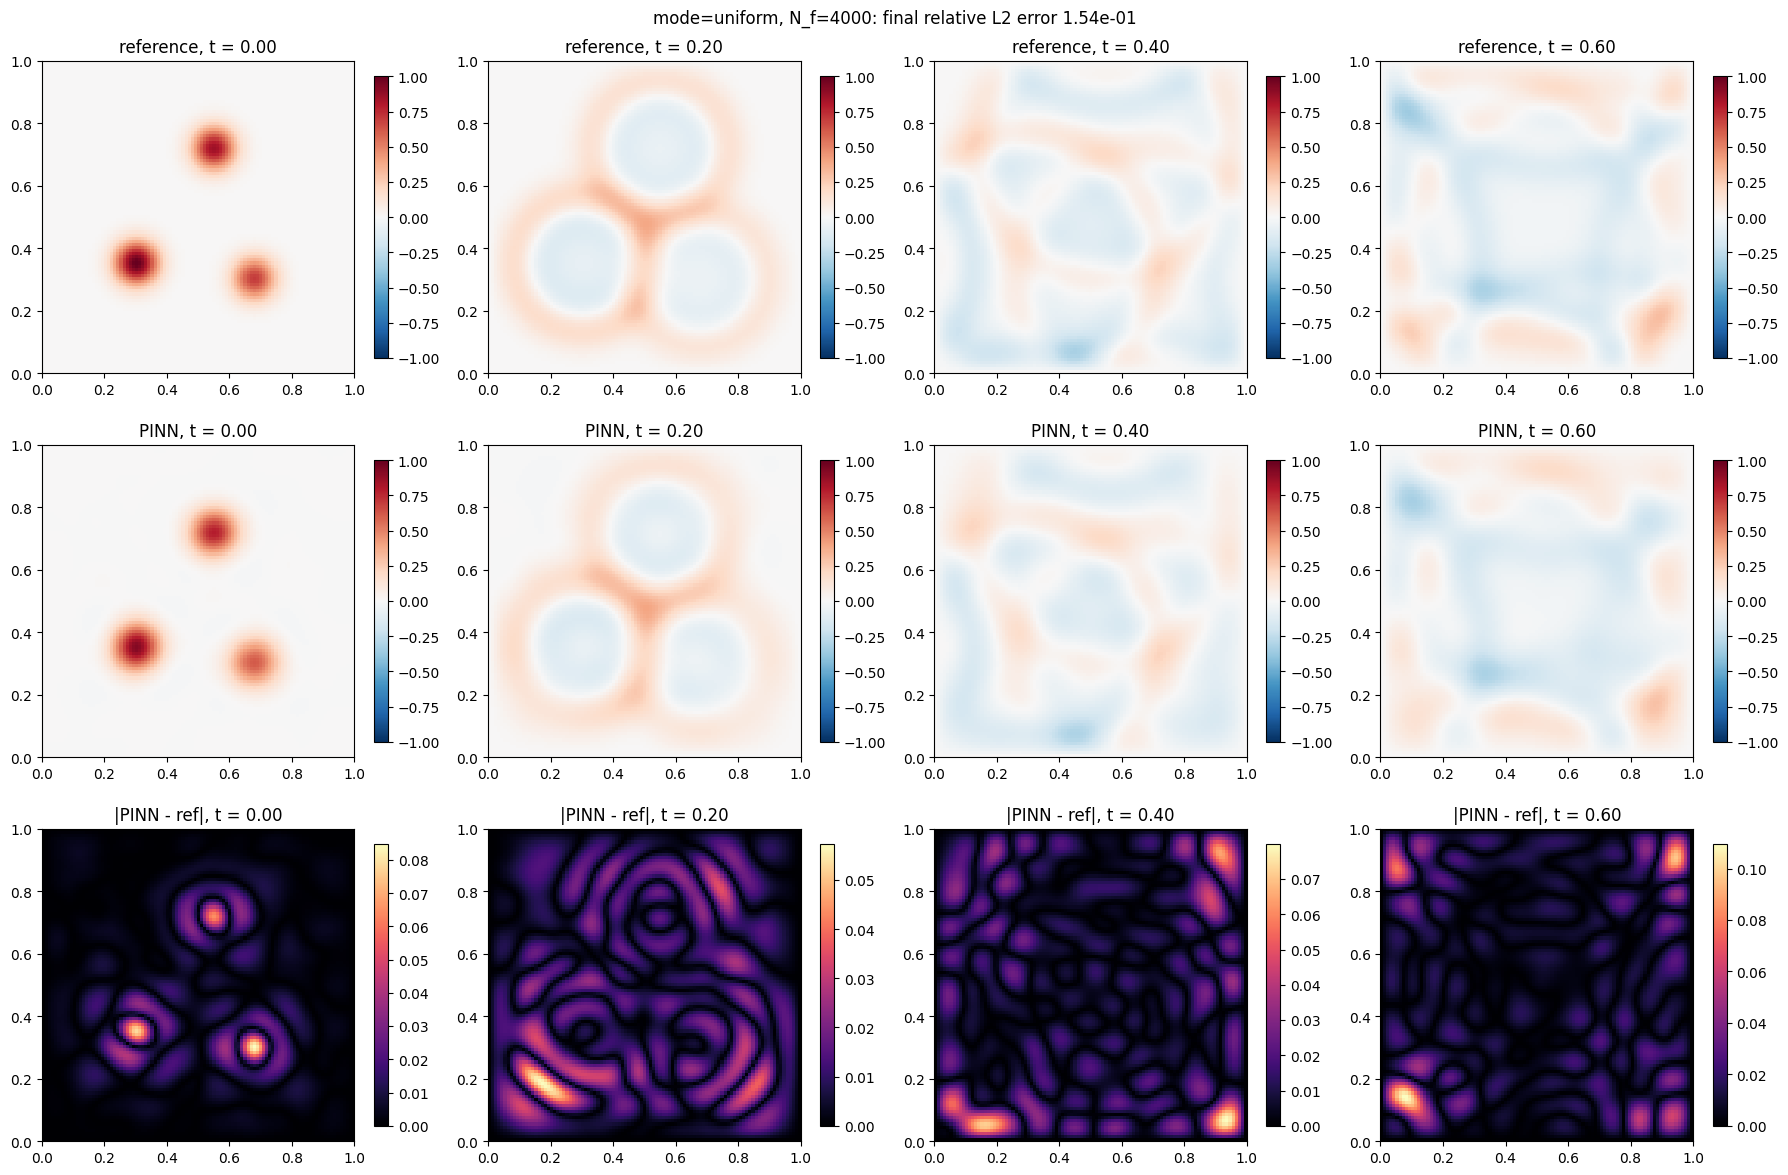

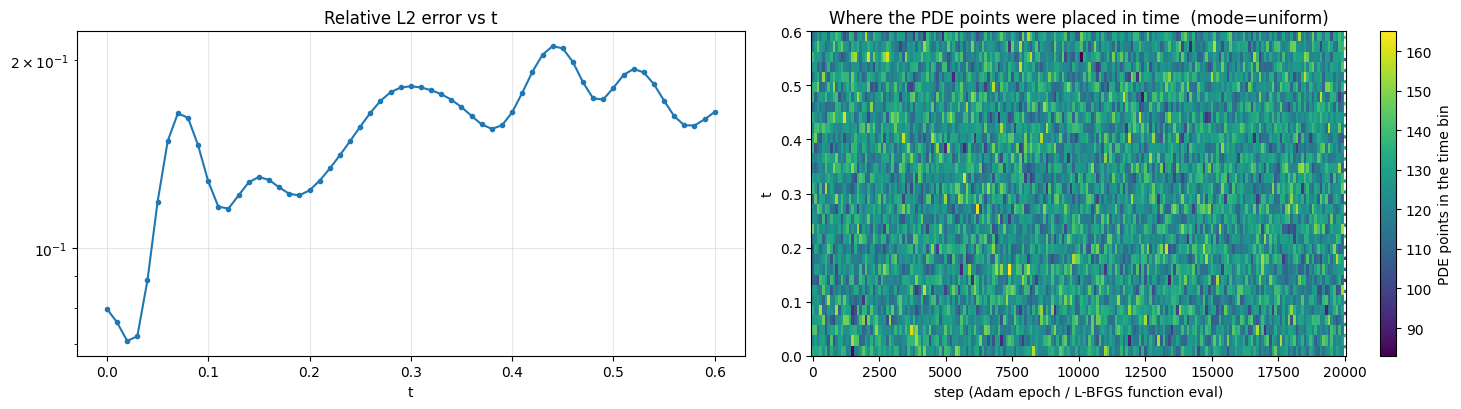

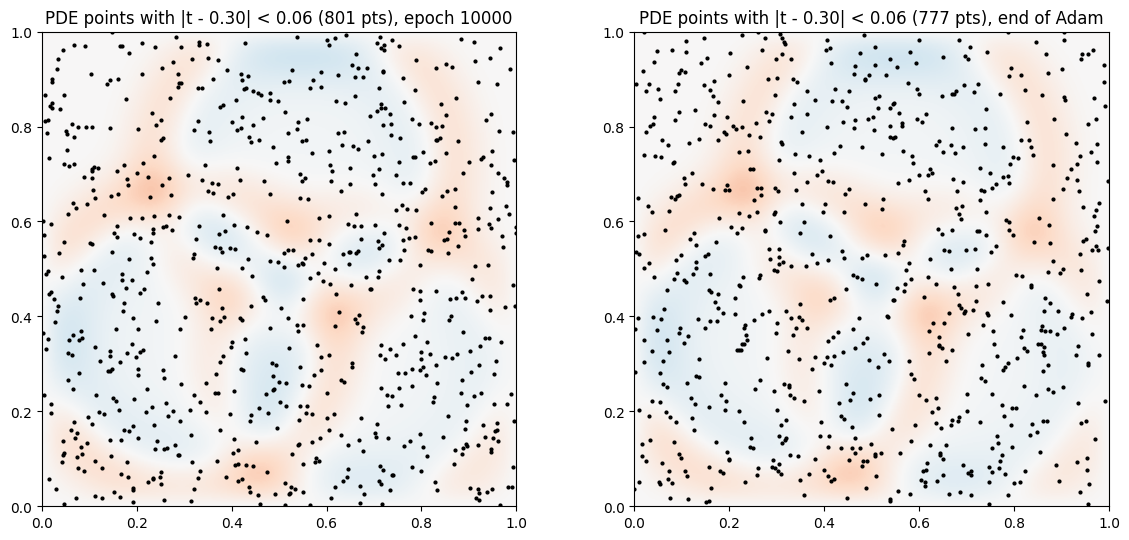

In [ ]:
def pinn_on_ref_grid(model, k, stride=4):
    xs = xs_ref[::stride]
    X, Y = np.meshgrid(xs, xs, indexing="xy")
    with torch.no_grad():
        U = model(to_t(X), to_t(Y), to_t(np.full(X.size, ts_ref[k]))).cpu().numpy().reshape(X.shape)
    return U, U_ref[k, ::stride, ::stride]


# (1) 스냅숏
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
vmax = np.abs(U_ref).max()
for j, k in enumerate(show_k):
    U_p, U_r = pinn_on_ref_grid(model, k)
    for i, (Z, name, cmap, lim) in enumerate([(U_r, "reference", "RdBu_r", vmax), (U_p, "PINN", "RdBu_r", vmax),
                                              (np.abs(U_p - U_r), "|PINN - ref|", "magma", None)]):
        a = axes[i, j]
        im = a.imshow(Z, origin="lower", extent=[0, 1, 0, 1], cmap=cmap,
                      vmin=-lim if lim else 0, vmax=lim if lim else Z.max())
        a.set_title(f"{name}, t = {ts_ref[k]:.2f}")
        fig.colorbar(im, ax=a, shrink=0.8)
fig.suptitle(f"mode={res['mode']}, N_f={res['N_f']}: final relative L2 error {res['rel_final']:.2e}")
plt.tight_layout()
plt.show()

# (2) 시간별 오차, 시간 bin 별 점 개수
err_t = []
with torch.no_grad():
    for k in range(REF_NT):
        U_p, U_r = pinn_on_ref_grid(model, k)
        err_t.append(np.linalg.norm(U_p - U_r) / np.linalg.norm(U_r))
h = res["hist"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].semilogy(ts_ref, err_t, "o-", ms=3)
ax[0].set_title("Relative L2 error vs t")
ax[0].set_xlabel("t")
ax[0].grid(alpha=0.3)
cnt = np.array(h["counts"], dtype=float).T
im = ax[1].pcolormesh(h["step"], (np.arange(TM_CAUSAL_N_CHUNKS) + 0.5) / TM_CAUSAL_N_CHUNKS * T, cnt,
                      shading="nearest", cmap="viridis")
fig.colorbar(im, ax=ax[1], label="PDE points in the time bin")
ax[1].axvline(res["adam_steps"], ls="--", color="w")
ax[1].set_title(f"Where the PDE points were placed in time  (mode={res['mode']})")
ax[1].set_xlabel("step (Adam epoch / L-BFGS function eval)")
ax[1].set_ylabel("t")
plt.tight_layout()
plt.show()

# (3) 공간 배치: 시각 t* 근처의 PDE 점
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, key, title in [(ax[0], "mid", f"epoch {EPOCHS_ADAM // 2}"), (ax[1], "adam_end", "end of Adam")]:
    xp, yp, tp = res["snap"][key]
    k = REF_NT // 2
    near = np.abs(tp - ts_ref[k]) < T / 10
    a.imshow(U_ref[k], origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    a.scatter(xp[near], yp[near], s=4, c="k")
    a.set_title(f"PDE points with |t - {ts_ref[k]:.2f}| < {T / 10:.2f} ({near.sum()} pts), {title}")
plt.tight_layout()
plt.show()

# **7번 비교 실험: 세 방식 × 여러 $N_f$**

`SWEEP_MODES` × `SWEEP_NF` × `SWEEP_SEEDS` 를 차례로 학습합니다(6번과 같은 조합은 다시 돌리지 않음). 결과는 `pulse_sweep.json` 에 저장됩니다.
0번 셀의 `RUN_SWEEP = True` 일 때만 실행합니다. **먼저 6번에서 `uniform`, `N_f = 4000` 이 학습되는지(최종 오차가 충분히 작은지) 확인하세요.** 균등 샘플링이 점이 넉넉해도 실패하는 설정에서는 샘플링 비교가 의미가 없습니다.

- 왼쪽: **최종 상대 L2 오차 vs PDE 점 수 $N_f$**. 같은 오차를 더 적은 점으로 내면 그 샘플링이 효율적인 것입니다.
- 가운데: Adam 끝 오차 vs $N_f$.
- 오른쪽: 가장 작은 $N_f$ 에서 오차 vs 누적 PDE 점 계산 수.

T4 GPU 에서 실행 하나에 수 분, 전체 12개에 수십 분 걸립니다. 빨리 보려면 0번 셀의 `QUICK = True`.

In [9]:
sweep = []
if RUN_SWEEP:
    for mode in SWEEP_MODES:
        for n_f in SWEEP_NF:
            for seed in SWEEP_SEEDS:
                if (mode, n_f, seed) == (res["mode"], res["N_f"], res["seed"]):
                    r = res
                else:
                    _, r = run(mode, n_f, seed)
                sweep.append(r)
    keep = ["mode", "N_f", "seed", "rel_final", "rel_adam", "time", "n_eval"]
    with open("pulse_sweep.json", "w") as f:
        json.dump([{k: r[k] for k in keep} | {"rel": r["hist"]["rel"], "n_eval_hist": r["hist"]["n_eval"]}
                   for r in sweep], f)
    print(f"\n{'mode':<10}{'N_f':>6}{'seed':>6}{'final relL2':>14}{'Adam end':>12}{'time [s]':>10}{'PDE evals':>12}")
    for r in sweep:
        print(f"{r['mode']:<10}{r['N_f']:>6}{r['seed']:>6}{r['rel_final']:>14.3e}{r['rel_adam']:>12.3e}"
              f"{r['time']:>10.0f}{r['n_eval']:>12.3e}")

===== mode=uniform, N_f=1000, seed=0 =====
  Epoch     0/20000 | loss 3.681e-02 | PDE 4.23e-03 | IC 1.55e-02 | relL2 9.899e-01 | N_pde 1000 | eps 10 min_w 0.000 | 0s, 남은 13.0분
  epoch당 29 ms -> Adam 남은 시간 약 9.6분
  Epoch  1000/20000 | loss 6.006e-03 | PDE 4.01e-03 | IC 4.95e-04 | relL2 1.017e+00 | N_pde 1000 | eps 10 min_w 0.000 | 31s, 남은 9.7분
  Epoch  2000/20000 | loss 5.880e-03 | PDE 3.67e-03 | IC 4.70e-04 | relL2 1.018e+00 | N_pde 1000 | eps 10 min_w 0.000 | 61s, 남은 9.1분
  Epoch  3000/20000 | loss 5.675e-03 | PDE 3.68e-03 | IC 3.95e-04 | relL2 7.620e-01 | N_pde 1000 | eps 10 min_w 0.000 | 91s, 남은 8.6분
  Epoch  4000/20000 | loss 5.598e-03 | PDE 3.59e-03 | IC 4.91e-04 | relL2 4.687e-01 | N_pde 1000 | eps 10 min_w 0.000 | 122s, 남은 8.2분
  Epoch  5000/20000 | loss 5.385e-03 | PDE 3.60e-03 | IC 3.64e-04 | relL2 3.684e-01 | N_pde 1000 | eps 10 min_w 0.000 | 152s, 남은 7.6분
  Epoch  6000/20000 | loss 5.400e-03 | PDE 3.64e-03 | IC 4.13e-04 | relL2 3.394e-01 | N_pde 1000 | eps 10 min_w 0.046 | 1

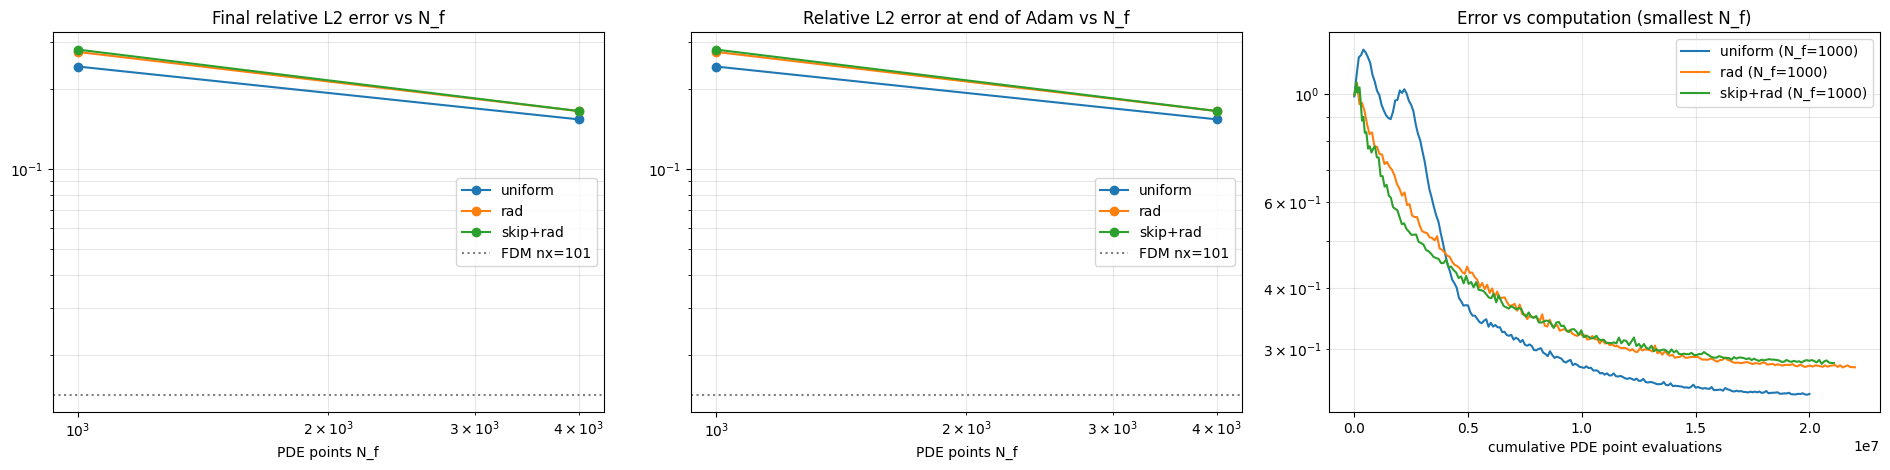

In [10]:
if sweep:
    fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
    for mode in SWEEP_MODES:
        rs = [r for r in sweep if r["mode"] == mode]
        nfs = sorted({r["N_f"] for r in rs})
        for a, key in [(ax[0], "rel_final"), (ax[1], "rel_adam")]:
            ys = [np.exp(np.mean([np.log(r[key]) for r in rs if r["N_f"] == n])) for n in nfs]   # seed 기하평균
            line, = a.loglog(nfs, ys, "o-", label=mode)
            for r in rs:
                a.plot(r["N_f"], r[key], ".", color=line.get_color(), alpha=0.5)
        r0 = [r for r in rs if r["N_f"] == min(nfs)][0]
        ax[2].semilogy(r0["hist"]["n_eval"], r0["hist"]["rel"], "-", label=f"{mode} (N_f={r0['N_f']})")
    for a, title in [(ax[0], "Final relative L2 error vs N_f"), (ax[1], "Relative L2 error at end of Adam vs N_f")]:
        a.set_title(title)
        a.set_xlabel("PDE points N_f")
        a.axhline(fdm_cmp_err, ls=":", color="gray", label=f"FDM nx={FDM_CMP_NX}")
    ax[2].set_title("Error vs computation (smallest N_f)")
    ax[2].set_xlabel("cumulative PDE point evaluations")
    for a in ax:
        a.grid(alpha=0.3, which="both")
        a.legend()
    plt.tight_layout()
    plt.show()

# **결과와 해석**

> **1차 실행**: Colab T4 GPU, 기본 설정(2026-11-20). L-BFGS 버그(아래 2-2)를 고치기 전 코드였습니다. 이 실행의 출력은 2차 실행으로 덮어써졌고, 수치는 아래 표에 남아 있습니다.

### 1. 이번 실행 결과

6번의 "학습되는지 확인" 실행 하나만 돌았습니다. 7번 비교 실험은 `RUN_SWEEP = False` 라 실행되지 않았습니다.

| 항목 | 값 |
|---|---|
| 설정 | `uniform`, $N_f=4000$, seed 0, Adam 10000 → L-BFGS 20×50, $\sigma=0.05$, $T=0.6$, `W_PDE = 1` |
| 기준해 점검 | 격자 201 과 401 의 상대 차이 $2.84\times10^{-3}$ → 기준해는 충분히 정확 |
| FDM (nx=101) | 상대 L2 오차 $1.42\times10^{-2}$, 계산 0.012 s |
| PINN, Adam 끝 | 상대 L2 오차 **0.444** |
| PINN, 최종 (L-BFGS 후) | 상대 L2 오차 **0.529** (L-BFGS 에서 오히려 나빠짐) |
| 학습 시간 | 314 s (Adam 64 ms/epoch × 10000 = 299 s, L-BFGS 15 s) |

Adam 단계의 오차는 epoch 1000 에서 0.67, 3000 에서 0.56, 5000 에서 0.50, 10000 에서 0.44 로 **끝까지 천천히 줄고 있었습니다.**

그림으로 본 것:
- **시간별 오차**: $t=0$ 에서 0.005 로 초기조건은 잘 맞습니다. 그런데 $t=0.05$ 에서 0.14, $t=0.1$ 에서 0.35 로 출발 직후부터 커지고, $t\ge0.3$ 에서는 0.6 ~ 0.7 입니다.
- **스냅숏**: $t=0.2$ 에서 PINN 의 고리 모양 파면이 기준해보다 약하고 넓게 퍼져 있습니다. 파동이 퍼져 나가면서 진폭을 잃는, 실제보다 매끄러운 해를 배운 것입니다. $t=0.4,\ 0.6$ 에서는 거의 평평합니다.
- **점 배치**: `uniform` 이므로 시간·공간 모두 고르게 놓였습니다(정상).

**결론: 점이 넉넉한 균등 샘플링도 이 문제를 학습하지 못했습니다.** 따라서 세 샘플링 방식의 비교는 아직 의미가 없고, 먼저 학습이 되는 설정을 찾아야 합니다.

### 2. 원인

**2-1. 인과성 가중치가 사실상 꺼져 있었습니다.** PDE 잔차에 $\sigma^2=0.0025$ 를 곱해서 시간 구간별 PDE 손실이 약 $2\times10^{-4}$ 로 작습니다. 그러면 $\varepsilon=10$ 이어도 $w_i=\exp(-\varepsilon\sum_{j<i}L_j)\approx0.93$ 이라, "앞 시간대부터 맞추라"는 압력이 거의 없습니다. 로그에서 $\varepsilon=1$ 단계는 epoch 약 1500 에 모든 가중치가 0.99 를 넘어 바로 끝났고, 이후 `min_w` 는 0.92 ~ 0.93 이었습니다. 오차가 출발 직후($t\approx0.05\sim0.1$)부터 커지는 것과 맞습니다.

**2-2. L-BFGS 버그 (수정함).** 초기조건 손실의 점을 손실을 계산할 때마다 새로 뽑고 있었습니다. 그래서 L-BFGS 의 목적함수가 평가할 때마다 조금씩 달라져 line search 가 제대로 작동하지 않았습니다. 20 chunk 가 15 s 만에 끝난 것과, 오차가 0.44 에서 0.53 으로 커진 것이 그 증상입니다. 이제는 L-BFGS 를 시작할 때 초기조건 점을 한 번 뽑아 고정합니다. 같은 파라미터에서 손실을 두 번 계산하면 같은 값이 나오는 것을 확인했고, CPU 짧은 시험에서 chunk 당 반복 수가 36 회에서 50 회(최대)로 늘었습니다.

다만 같은 짧은 시험(Adam 1000 epoch)에서는 수정 후에도 L-BFGS 동안 오차가 0.88 → 0.95 로 커졌습니다. 손실을 줄이는 방향이 오차를 줄이는 방향과 다르다는 뜻으로, 2-1 의 손실 균형 문제가 남아 있음을 보여 줍니다.

### 3. 다음 실행 (0번 셀에서 한 번에 하나씩)

| 순서 | 설정 | 확인할 것 |
|---|---|---|
| 1 | `W_PDE = 100`, `EPOCHS_ADAM = 20000` | 로그의 `min_w` 가 처음에 0 근처에서 시작해 차츰 1 로 올라가는가(인과성 가중치가 작동하는가). 상대 오차가 0.44 보다 내려가는가 |
| 2 | (1 로 안 되면) `W_PDE = 1`, `TM_CAUSAL_EPS_LIST = [100.0, 1000.0, 10000.0]` | 같은 효과를 eps 로 냅니다. Adam 초반에는 뒤 시간대를 일부러 미루므로 전체 오차가 1 이상으로 보일 수 있습니다 |
| 3 | `FOURIER_SIGMA = 1 ~ 4`, `WIDTH, DEPTH = 128, 4` | 펄스 폭에 맞는 주파수를 표현하게 합니다 |
| 4 | `SIGMA = 0.08` 또는 `T = 0.3` | 문제를 덜 어렵게 만듭니다 |

CPU 에서 Adam 1000 epoch 만 돌린 짧은 시험에서는 1번(`W_PDE = 100`)이 기본값보다 조금 나았습니다(Adam 끝 0.854 → 0.825, L-BFGS 중 악화 폭도 작음). 시간이 짧아 결론으로 쓰기는 어렵습니다.

**최종 상대 오차가 0.05 아래(가능하면 FDM 의 0.014 근처)로 내려가는 설정을 찾으면** 0번 셀의 `RUN_SWEEP = True` 로 바꿔 7번 비교 실험을 돌리세요. 그 결과(7번의 표와 왼쪽 그래프)를 보고서 9.5절에 넣습니다.

---

## 2차 실행: `W_PDE = 100`, `EPOCHS_ADAM = 20000`

> 2차 실행: 2026-11-20, L-BFGS 수정 후 코드. 이 실행의 출력은 3차 실행으로 덮어써졌습니다.

### 결과 (`uniform`, $N_f=4000$, seed 0)

| 항목 | 1차 (`W_PDE = 1`, Adam 10000) | **2차 (`W_PDE = 100`, Adam 20000)** |
|---|---|---|
| Adam 끝 상대 오차 | 0.444 | **0.171** |
| 최종 (L-BFGS 후) | 0.529 | **0.268** |
| `min_w` (인과성 가중치 최솟값) | 0.92 ~ 0.93 (처음부터) | 0.11 에서 시작 → 0.97 |
| 학습 시간 | 314 s | 645 s (Adam 607 s, 약 30 ms/epoch; L-BFGS 38 s) |

Adam 단계 오차 추이: epoch 1000 에서 0.59, 5000 에서 0.26, 10000 에서 0.20, 20000 에서 0.17. 끝까지 조금씩 줄고 있었습니다.

- **크게 나아졌습니다.** 이번에는 인과성 가중치가 실제로 작동했습니다(`min_w` 가 0.11 에서 시작). Adam 끝 오차가 0.44 에서 0.17 로 줄었습니다.
- **파면의 모양과 위치는 이제 맞습니다.** 스냅숏에서 $t=0.2$ 의 세 고리, $t=0.4,\ 0.6$ 의 반사 무늬가 기준해와 같은 모양입니다. 남은 오차는 주로 고리의 **진폭** 차이입니다.
- **오차는 출발 직후에 생깁니다.** 시간별 오차가 $t=0$ 에서 0.006, $t=0.04$ 에서 0.10, $t=0.08$ 에서 0.25 로 커진 뒤, 이후에는 0.25 ~ 0.33 으로 거의 일정합니다. 펄스가 처음 갈라져 퍼지는 순간을 정확히 맞추지 못하고, 그 오차가 그대로 실려 가는 모양입니다.

### 남은 문제

1. **출발 직후의 오차.** 인과성 가중치가 작동은 했지만 `min_w` 가 0.99 를 넘지 못해 eps 가 끝까지 1 에 머물렀습니다. 앞 시간대를 더 엄격하게 먼저 맞추게 할 여지가 있습니다.
2. **L-BFGS 가 여전히 오차를 키웁니다(0.171 → 0.268).** 목적함수 버그는 고쳤으므로 이번에는 다른 원인입니다. 고정된 4000 점에 대한 과적합으로 보입니다. Adam 은 매 epoch 점을 새로 뽑아 사실상 아주 많은 점을 보지만, L-BFGS 는 같은 4000 점만 봅니다. 좁은 펄스 문제에서는 4000 점이 시공간을 덮기에 부족하고, 점 사이에서 해가 틀어집니다.

### 다음 실행 제안

| 설정 | 이유 |
|---|---|
| `USE_LBFGS = False` | 이 문제에서는 L-BFGS 가 정확도를 떨어뜨립니다. 샘플링 비교는 Adam 끝 오차로 합니다 |
| `TM_CAUSAL_EPS_LIST = [10.0, 100.0, 1000.0]` | 출발 직후 시간대를 더 강하게 먼저 맞추게 합니다(문제 1) |
| `RUN_SWEEP = True`, `SWEEP_NF = [1000, 4000]` | 3 방식 × 2 = 6 실행, T4 에서 약 1시간 |

오차 0.17 수준이라도 같은 조건에서 방식끼리 비교하는 것은 의미가 있습니다. **핵심 질문은 "같은 $N_f$ 에서 `rad`, `skip+rad` 의 오차가 `uniform` 보다 낮은가, 특히 점이 적은 $N_f=1000$ 에서 차이가 커지는가"** 입니다. 시간이 부족하면 eps 는 그대로 두고 앞의 두 설정만 바꿔도 됩니다.

---

## 3차 실행과 비교 실험: `W_PDE = 100`, `TM_CAUSAL_EPS_LIST = [10, 100, 1000]`, `USE_LBFGS = False`, Adam 20000

> **위 셀들의 출력은 이 3차 실행과 비교 실험의 결과입니다**(2026-11-21 저장). 2차 실행의 수치는 위 표에 남아 있습니다.

### 확인 실행 (6번, `uniform`, $N_f=4000$)
- 상대 오차 **0.154** (2차 0.171, L-BFGS 후 0.268 보다 좋음). L-BFGS 를 끈 효과가 큽니다.
- `min_w` 가 0.000 에서 시작해 끝에 0.71. 인과성 가중치가 강하게 작동했습니다.
- 시간별 오차가 0.08 ~ 0.21 로 시간 전체에 고르게 퍼졌습니다(2차에서는 출발 직후 0.25 로 급증). 대신 $t=0$ 의 오차가 0.006 → 0.08 로 커졌습니다.

### 비교 실험 (7번, seed 0)

| 방식 | $N_f=1000$ | $N_f=4000$ | 학습 시간 (1000 / 4000) | 누적 PDE 점 계산 (1000 / 4000) |
|---|---|---|---|---|
| `uniform` | **0.242** | **0.154** | 607 s / 611 s | 2.00e7 / 8.00e7 |
| `rad` | 0.275 | 0.165 | 624 s / 628 s | 2.20e7 / 8.80e7 |
| `skip+rad` | 0.281 | 0.165 | 635 s / 650 s | 2.11e7 / 8.63e7 |
| (참고) FDM nx=101 | 0.014 | | 0.01 s | |

- **최종 오차는 두 점 수 모두 `uniform` 이 가장 낮았습니다.** 적응 방식은 7 ~ 16% 높았고, 점이 적은 $N_f=1000$ 에서 차이가 더 컸습니다. 기대와 반대 방향입니다.
- **학습 초반은 적응 방식이 빨랐습니다.** 오른쪽 그래프($N_f=1000$)에서 `rad` 계열은 처음부터 꾸준히 내려가 0.5 에 먼저 도달하지만, `uniform` 은 초반 약 3000 epoch 동안 1 근처에서 진동합니다. 누적 계산 약 5e6 이후로는 `uniform` 이 앞서고 끝까지 유지됩니다.
- **건너뛰기는 계산을 4% 만 줄였습니다.** 닫힌 시간대가 일찍 열렸습니다.
- **적응 방식은 3 ~ 6% 더 오래 걸렸습니다.** 후보 점의 잔차 계산 비용입니다.

### 해석 (추정)
1. **"좁은 펄스" 가 국소적인 시간이 짧습니다.** 기준해 그림에서 $t=0.2$ 까지는 좁은 고리지만, $t\ge0.4$ 에서는 반사파가 영역 전체를 덮습니다. $T=0.6$ 의 절반 이상은 점을 몰아 줄 곳이 뚜렷하지 않습니다.
2. **오차가 잔차가 큰 곳에 있지 않습니다.** 오차 맵에서 오차는 파면 위치보다 고리 진폭과 초기 펄스 주변에 있습니다. `rad` 의 초기조건 손실이 `uniform` 보다 약 1.5 배 컸습니다($N_f=1000$: 3.7e-4 대 2.3e-4). 잔차가 큰 곳에 점을 모으는 대신, 오차의 실제 원인이 덜 학습된 것으로 보입니다.
3. **seed 가 하나라** 정량적 차이는 불확실하지만, 두 점 수에서 같은 방향입니다.

### 결론
v4 의 매끄러운 문제(이득 없음)와 합치면, **잔차 기반 샘플링은 학습 초반 수렴을 앞당길 수는 있지만 최종 정확도를 항상 높이지는 않습니다.** 잔차의 크기가 오차가 생기는 곳을 가리킬 때만 이득을 기대할 수 있습니다. 두 문제 모두에서 PINN 은 같은 문제를 0.01 초에 푸는 FDM(nx=101)보다 오차가 컸습니다(여기서는 0.15 대 0.014). 보고서 9.5 절에 같은 내용을 정리했습니다.

### 더 해 볼 수 있는 것
- `T = 0.25`: 반사 전, 파면이 실제로 국소적인 구간만 학습합니다. 적응 샘플링이 유리할 가능성이 가장 큰 조건입니다.
- `AS_C = 5`: 균등 성분을 늘린 잔차 기반 샘플링입니다. 초기조건 근처가 덜 비게 합니다.
- `SWEEP_SEEDS = [0, 1]`: 차이가 우연인지 확인합니다.
